# Stage 10 — SHAP interpretation, one step at a time

This notebook explains the final **ExtraTrees** and **CatBoost** models from Stage 08 using the fixed **250 Stage 05 features**. Run cells from top to bottom. Each analysis cell displays a short result or figure before you continue, and saves the corresponding tables and figures under `outputs/10_shap_interpretation/`.

SHAP is calculated for the locked test molecules. Test activity values are not loaded or used. Local examples are chosen from each model’s predicted pIC50 values (lowest, median, highest).

In [2]:
# 1. Locate the project and import the packages used in this notebook.
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "src").is_dir():
    raise FileNotFoundError("Could not find the project src/ directory. Open this notebook from the project folder.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print(f"Project folder: {PROJECT_ROOT}")
print("Next: check that the outputs from Stages 03, 04, 05, and 08 are present.")

Project folder: c:\Users\USER\Documents\E\Code
Next: check that the outputs from Stages 03, 04, 05, and 08 are present.


In [3]:
# 2. Check required inputs and create this stage's output folders.
import joblib
import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt
from IPython.display import display
from src.utils import OUTPUTS, setup_plotting

MODELS = ["ExtraTreesRegressor", "CatBoostRegressor"]
TOP_GLOBAL = 20
TOP_LOCAL = 15
FEATURE_FILE = OUTPUTS / "03_feature_generation/tables/all_features.parquet"
TEST_IDS_FILE = OUTPUTS / "04_train_test_split/tables/test_ids.csv"
SELECTED_FILE = OUTPUTS / "05_feature_selection/tables/selected_features.csv"
PREDICTIONS_FILE = OUTPUTS / "08_final_model_evaluation/tables/locked_test_predictions_all_models.csv"
MODELS_DIR = OUTPUTS / "08_final_model_evaluation/models"
SHAP_DIR = OUTPUTS / "10_shap_interpretation"
TABLE_DIR = SHAP_DIR / "tables"
FIGURE_DIR = SHAP_DIR / "figures"
for folder in (TABLE_DIR, FIGURE_DIR):
    folder.mkdir(parents=True, exist_ok=True)

required = [FEATURE_FILE, TEST_IDS_FILE, SELECTED_FILE, PREDICTIONS_FILE]
required += [MODELS_DIR / f"final_{name}.joblib" for name in MODELS]
missing = [path for path in required if not path.is_file()]
if missing:
    raise FileNotFoundError("Missing prerequisite output(s):\n" + "\n".join(map(str, missing)) + "\nRun the named earlier stages first.")

setup_plotting()
print("All prerequisite files are present.")
print(f"SHAP version: {shap.__version__}")
print(f"Output folder: {SHAP_DIR}")
print("Next: load and validate the fixed features, locked test IDs, Stage 08 predictions, and saved models.")

All prerequisite files are present.
SHAP version: 0.49.1
Output folder: C:\Users\USER\Documents\E\Code\outputs\10_shap_interpretation
Next: load and validate the fixed features, locked test IDs, Stage 08 predictions, and saved models.


In [4]:
# 3. Load the fixed Stage 05 features and locked test rows; validate alignment.
selected_features = pd.read_csv(SELECTED_FILE)["feature"].astype(str).tolist()
if len(selected_features) != 250 or len(set(selected_features)) != 250:
    raise ValueError(f"Expected 250 unique Stage 05 features; found {len(selected_features)}.")

test_ids = pd.read_csv(TEST_IDS_FILE, dtype={"chembl_id": str})
test_ids["chembl_id"] = test_ids["chembl_id"].astype(str)
if test_ids["chembl_id"].duplicated().any():
    raise ValueError("The locked test-ID file contains duplicate molecule IDs.")

X_all = pd.read_parquet(FEATURE_FILE)
X_all.index = X_all.index.astype(str)
missing_features = sorted(set(selected_features) - set(X_all.columns))
missing_ids = sorted(set(test_ids["chembl_id"]) - set(X_all.index))
if missing_features or missing_ids:
    raise ValueError(f"Missing features: {missing_features[:10]}; missing test IDs: {len(missing_ids)}")
X_test = X_all.reindex(test_ids["chembl_id"]).loc[:, selected_features]
X_test = X_test.apply(pd.to_numeric, errors="coerce")
if not np.isfinite(X_test.to_numpy(dtype=float)).all():
    raise ValueError("Test features contain missing or infinite values; this pipeline does not impute.")

predictions = pd.read_csv(PREDICTIONS_FILE, dtype={"chembl_id": str})
predictions["chembl_id"] = predictions["chembl_id"].astype(str)
predictions = predictions.loc[predictions["model"].isin(MODELS)].copy()
if set(predictions["model"].unique()) != set(MODELS):
    raise ValueError("Stage 08 predictions must include both ExtraTrees and CatBoost.")

print(f"Fixed features: {len(selected_features)}")
print(f"Locked test molecules: {len(test_ids)}")
print(f"Feature matrix shape: {X_test.shape}")
print("First five feature names:", selected_features[:5])
print("Test target values were not loaded.")
display(predictions.groupby("model")["predicted_pIC50"].agg(["count", "min", "median", "max"]))
print("Next: load the final Stage 08 models and confirm they use these same 250 features.")

Fixed features: 250
Locked test molecules: 1283
Feature matrix shape: (1283, 250)
First five feature names: ['ecfp4_361', 'ecfp4_1164', 'ecfp4_318', 'mordred2d_ATSC1dv', 'mordred2d_SpMax_A']
Test target values were not loaded.


,count,min,median,max
model,,,,
CatBoostRegressor,1283,2.993360,6.164433,9.236537
ExtraTreesRegressor,1283,3.210712,6.179924,9.272691


Next: load the final Stage 08 models and confirm they use these same 250 features.


In [5]:
# 4. Load the final fitted models and verify their feature order.
model_bundles = {}
for model_name in MODELS:
    bundle = joblib.load(MODELS_DIR / f"final_{model_name}.joblib")
    model_features = list(bundle.get("feature_names", []))
    if model_features != selected_features:
        raise ValueError(f"{model_name} feature order differs from the fixed Stage 05 feature list.")
    model_bundles[model_name] = bundle
    print(f"{model_name}: loaded; {len(model_features)} matching features")
print("Next: calculate and validate ExtraTrees SHAP values.")

ExtraTreesRegressor: loaded; 250 matching features
CatBoostRegressor: loaded; 250 matching features
Next: calculate and validate ExtraTrees SHAP values.


In [6]:
# 5. Calculate ExtraTrees SHAP values, check additivity, and show global ranking.
model_name = "ExtraTreesRegressor"
model = model_bundles[model_name]["model"]
explainer = shap.TreeExplainer(model)
values = np.asarray(explainer.shap_values(X_test, check_additivity=False), dtype=float)
if values.shape != X_test.shape:
    raise ValueError(f"Unexpected SHAP dimensions {values.shape}; expected {X_test.shape}.")
base = np.asarray(explainer.expected_value, dtype=float).reshape(-1)
if base.size == 1:
    base = np.repeat(base[0], len(X_test))
elif base.size != len(X_test):
    raise ValueError(f"Unexpected SHAP base-value dimensions: {base.shape}")

model_predictions = predictions.loc[predictions["model"] == model_name].set_index("chembl_id")
if model_predictions.index.duplicated().any() or set(model_predictions.index) != set(test_ids["chembl_id"]):
    raise ValueError("ExtraTrees prediction IDs do not match the locked test IDs.")
model_predictions = model_predictions.reindex(test_ids["chembl_id"])
reconstructed = base + values.sum(axis=1)
max_error = float(np.max(np.abs(reconstructed - model_predictions["predicted_pIC50"].to_numpy(dtype=float))))
if not np.allclose(reconstructed, model_predictions["predicted_pIC50"].to_numpy(dtype=float), atol=1e-3, rtol=1e-3):
    raise ValueError(f"ExtraTrees SHAP additivity check failed; maximum absolute error={max_error:.6g}")

max_error_et = max_error
extra_trees_shap = shap.Explanation(values=values, base_values=base, data=X_test.to_numpy(dtype=float), feature_names=selected_features)
importance_et = pd.DataFrame({"feature": selected_features, "mean_abs_shap": np.abs(values).mean(axis=0), "mean_shap": values.mean(axis=0)}).sort_values("mean_abs_shap", ascending=False, kind="stable").reset_index(drop=True)
importance_et.insert(0, "model", model_name)
importance_et.to_csv(TABLE_DIR / "global_shap_importance_ExtraTreesRegressor.csv", index=False)
pd.DataFrame(values, columns=selected_features).assign(chembl_id=test_ids["chembl_id"].to_numpy()).to_parquet(TABLE_DIR / "test_shap_values_ExtraTreesRegressor.parquet", index=False)
pd.DataFrame([{"model": model_name, "n_test": len(X_test), "max_abs_additivity_error": max_error}]).to_csv(TABLE_DIR / "shap_additivity_ExtraTreesRegressor.csv", index=False)
print(f"SHAP matrix: {values.shape}; maximum additivity error: {max_error:.3g}")
print("Top 20 global features by mean absolute SHAP:")
display(importance_et.head(TOP_GLOBAL))
print("Next: inspect and save the ExtraTrees global plots.")

SHAP matrix: (1283, 250); maximum additivity error: 6.89e-07
Top 20 global features by mean absolute SHAP:


,model,feature,mean_abs_shap,mean_shap
0,ExtraTreesRegressor,ecfp4_361,0.287584,-0.104999
1,ExtraTreesRegressor,ecfp4_1164,0.138488,0.015830
2,ExtraTreesRegressor,ecfp4_1722,0.092061,0.010109
3,ExtraTreesRegressor,ecfp4_318,0.067803,0.007218
4,ExtraTreesRegressor,ecfp4_875,0.049211,-0.003136
5,ExtraTreesRegressor,ecfp4_917,0.045557,0.004075
6,ExtraTreesRegressor,ecfp4_1658,0.037239,0.007499
7,ExtraTreesRegressor,ecfp4_1409,0.034740,0.001135
8,ExtraTreesRegressor,ecfp4_1696,0.031501,0.001352
9,ExtraTreesRegressor,mordred2d_SpMax_A,0.028294,0.005932


Next: inspect and save the ExtraTrees global plots.


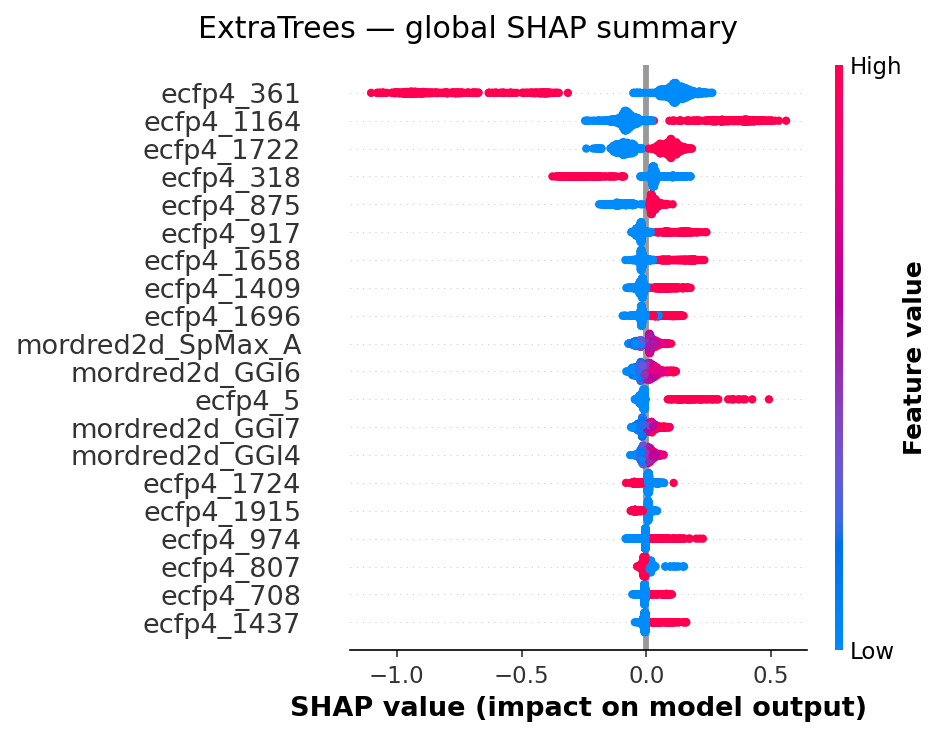

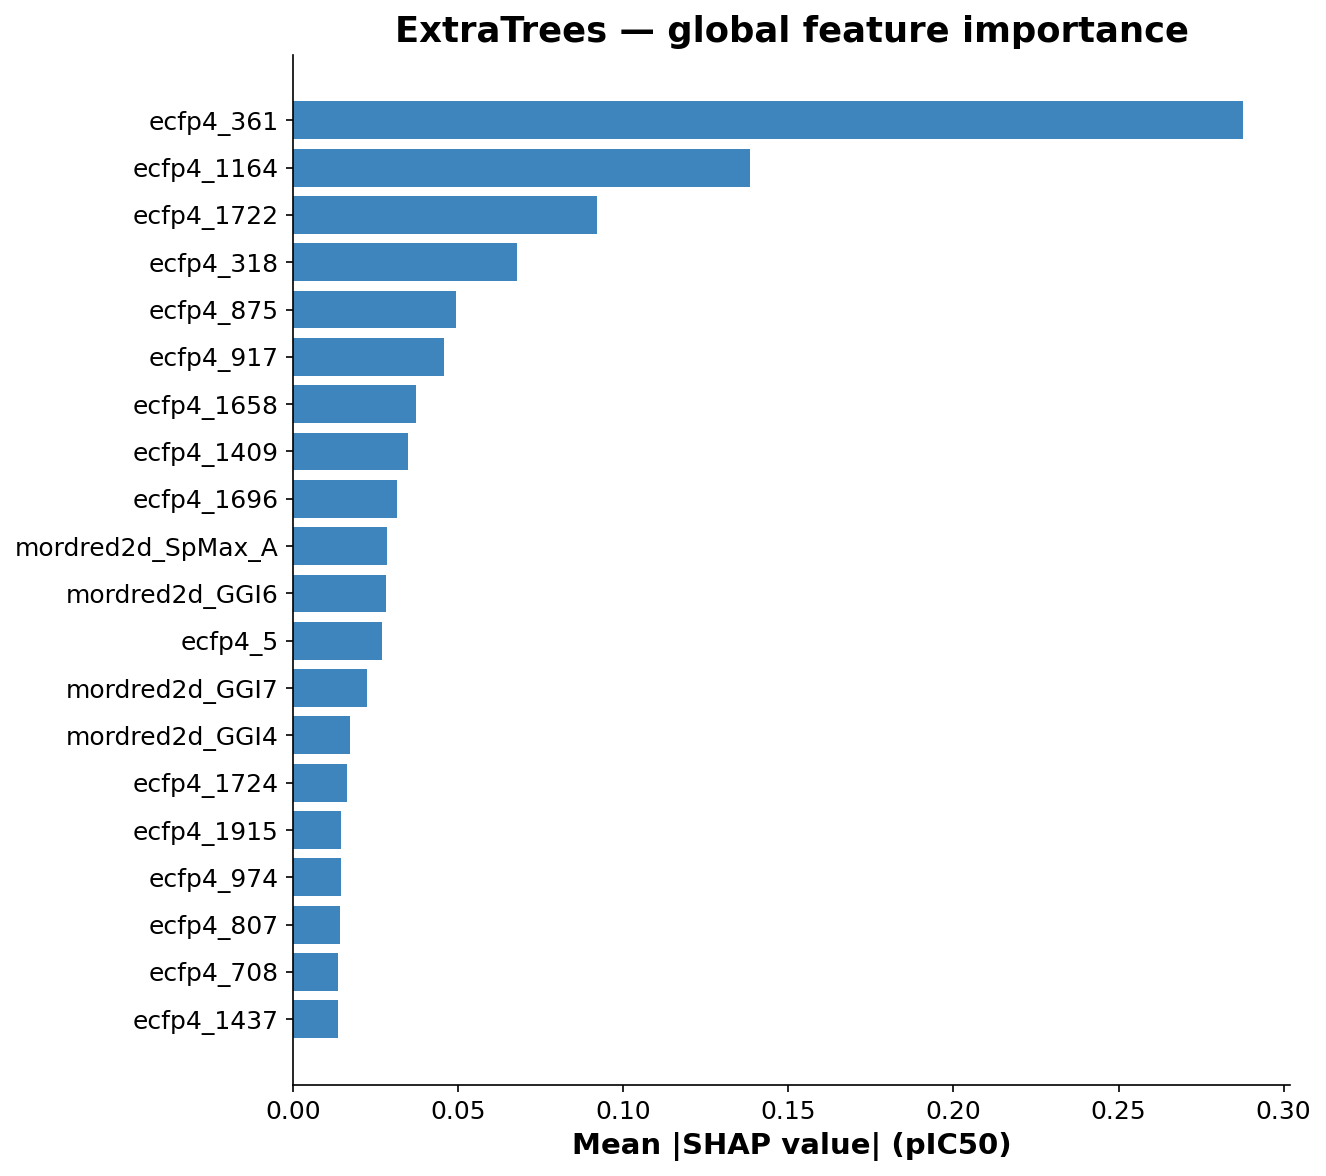

Both ExtraTrees global plots are displayed above and saved in the Stage 10 figures folder.
Next: select low, median, and high ExtraTrees predictions for local explanations.


In [7]:
# 6. ExtraTrees global SHAP plots: beeswarm and mean absolute importance.
top_et = importance_et.head(TOP_GLOBAL)
et_columns = [selected_features.index(feature) for feature in top_et["feature"]]
shap.summary_plot(values[:, et_columns], X_test.iloc[:, et_columns], feature_names=top_et["feature"].tolist(), max_display=TOP_GLOBAL, show=False, plot_size=None)
fig = plt.gcf()
fig.suptitle("ExtraTrees — global SHAP summary", y=1.02)
fig.savefig(FIGURE_DIR / "global_shap_beeswarm_ExtraTreesRegressor.png", dpi=300, bbox_inches="tight")
fig.savefig(FIGURE_DIR / "global_shap_beeswarm_ExtraTreesRegressor.pdf", bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(9, 8))
plot_et = top_et.iloc[::-1]
ax.barh(plot_et["feature"], plot_et["mean_abs_shap"], color="#2878B5", alpha=0.9)
ax.set_xlabel("Mean |SHAP value| (pIC50)")
ax.set_title("ExtraTrees — global feature importance")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "global_shap_bar_ExtraTreesRegressor.png", dpi=300, bbox_inches="tight")
fig.savefig(FIGURE_DIR / "global_shap_bar_ExtraTreesRegressor.pdf", bbox_inches="tight")
plt.show()
print("Both ExtraTrees global plots are displayed above and saved in the Stage 10 figures folder.")
print("Next: select low, median, and high ExtraTrees predictions for local explanations.")

In [8]:
# 7. Select ExtraTrees local cases using predictions only; display the selected molecules.
et_test_predictions = model_predictions.reset_index()[["chembl_id", "predicted_pIC50"]].sort_values("predicted_pIC50", kind="stable").reset_index(drop=True)
case_positions = {"lowest_predicted_pIC50": 0, "median_predicted_pIC50": len(et_test_predictions) // 2, "highest_predicted_pIC50": len(et_test_predictions) - 1}
et_cases = pd.DataFrame([{"case": label, "chembl_id": et_test_predictions.iloc[pos]["chembl_id"], "predicted_pIC50": float(et_test_predictions.iloc[pos]["predicted_pIC50"])} for label, pos in case_positions.items()]).drop_duplicates("chembl_id")
et_cases.insert(0, "model", "ExtraTreesRegressor")
et_cases.to_csv(TABLE_DIR / "local_shap_cases_ExtraTreesRegressor.csv", index=False)
display(et_cases)
print("These cases were chosen without using measured test activity.")
print("Next: inspect each molecule's local SHAP waterfall plot.")

,model,case,chembl_id,predicted_pIC50
0,ExtraTreesRegressor,lowest_predicted_pIC50,CHEMBL4763815,3.210712
1,ExtraTreesRegressor,median_predicted_pIC50,CHEMBL6033164,6.179924
2,ExtraTreesRegressor,highest_predicted_pIC50,CHEMBL6010533,9.272691


These cases were chosen without using measured test activity.
Next: inspect each molecule's local SHAP waterfall plot.


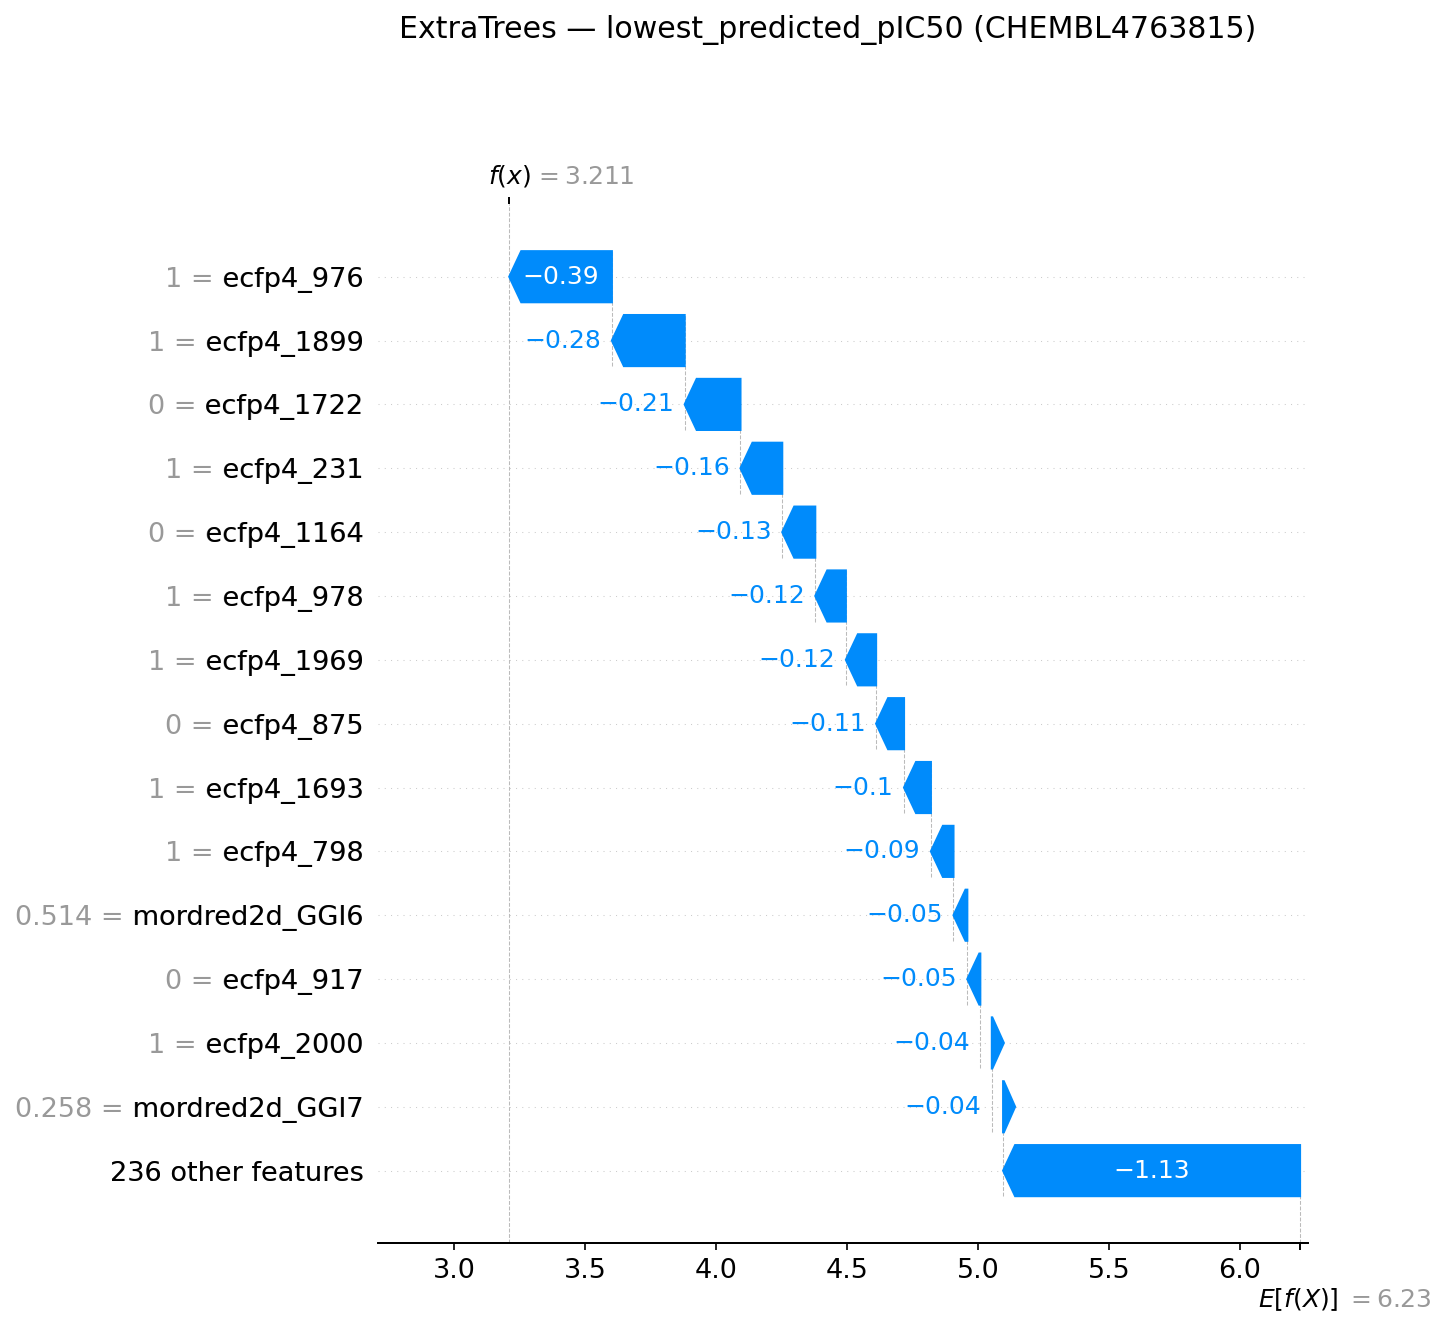

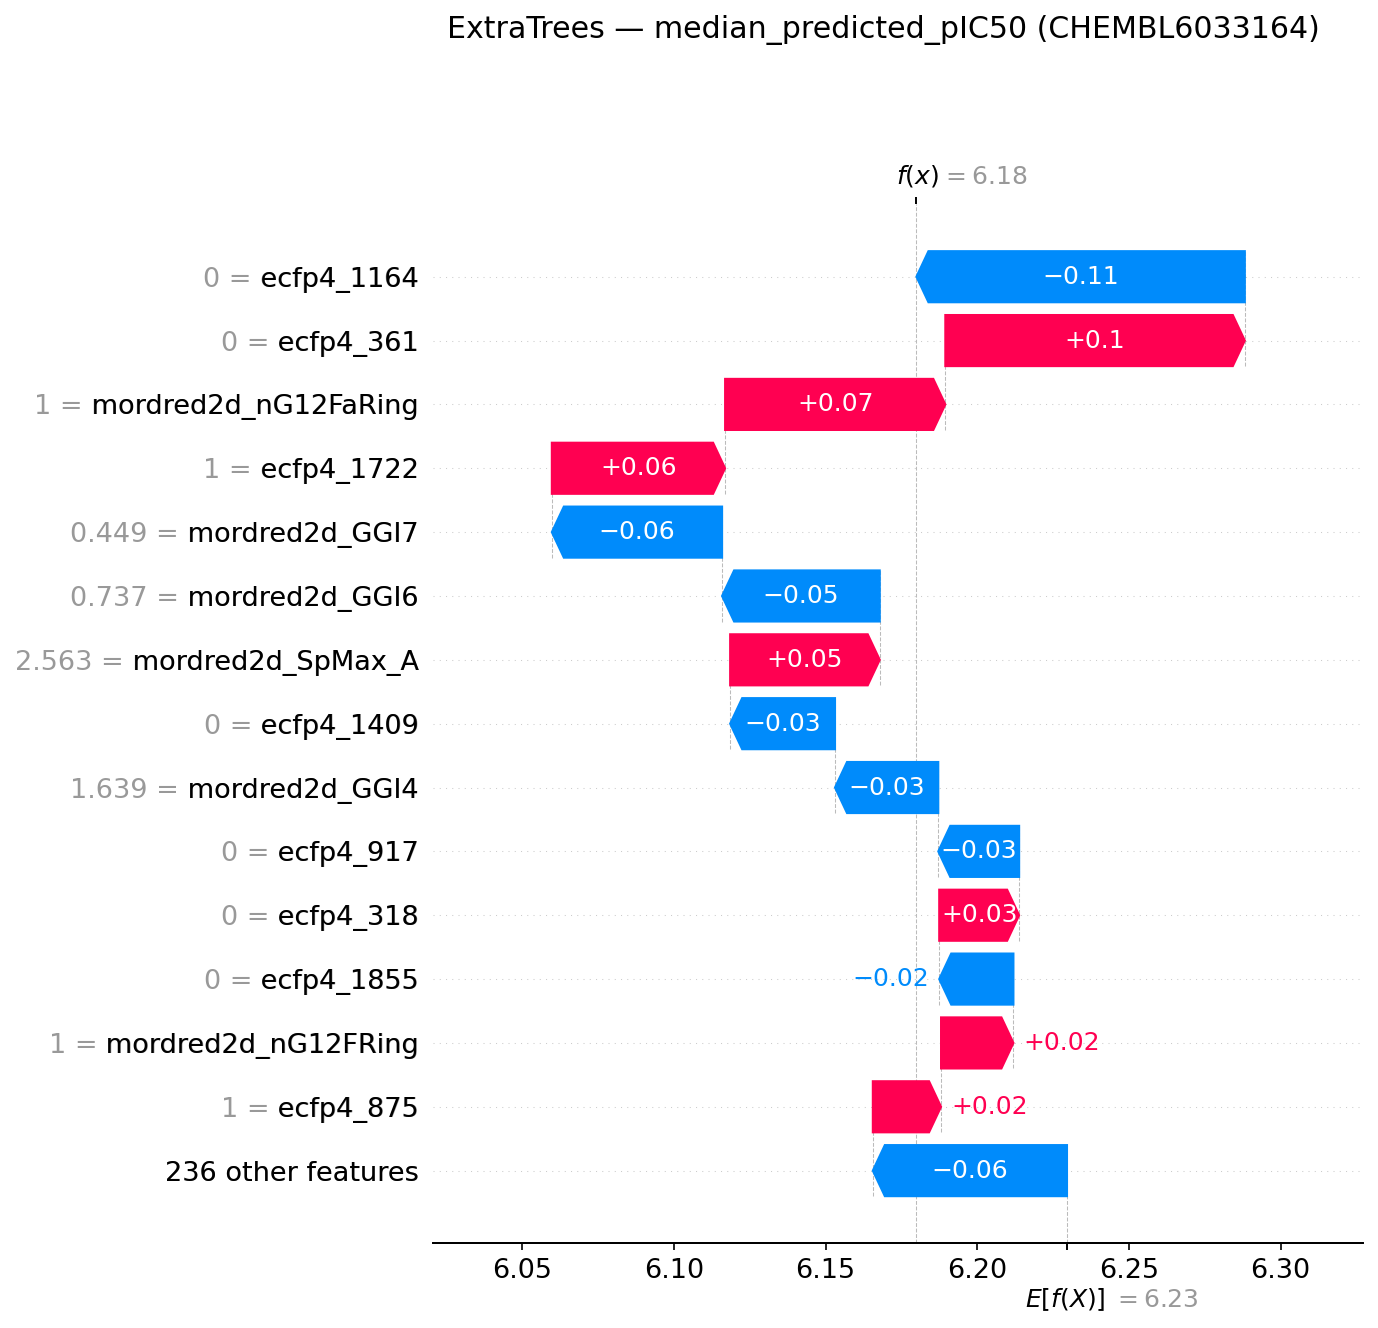

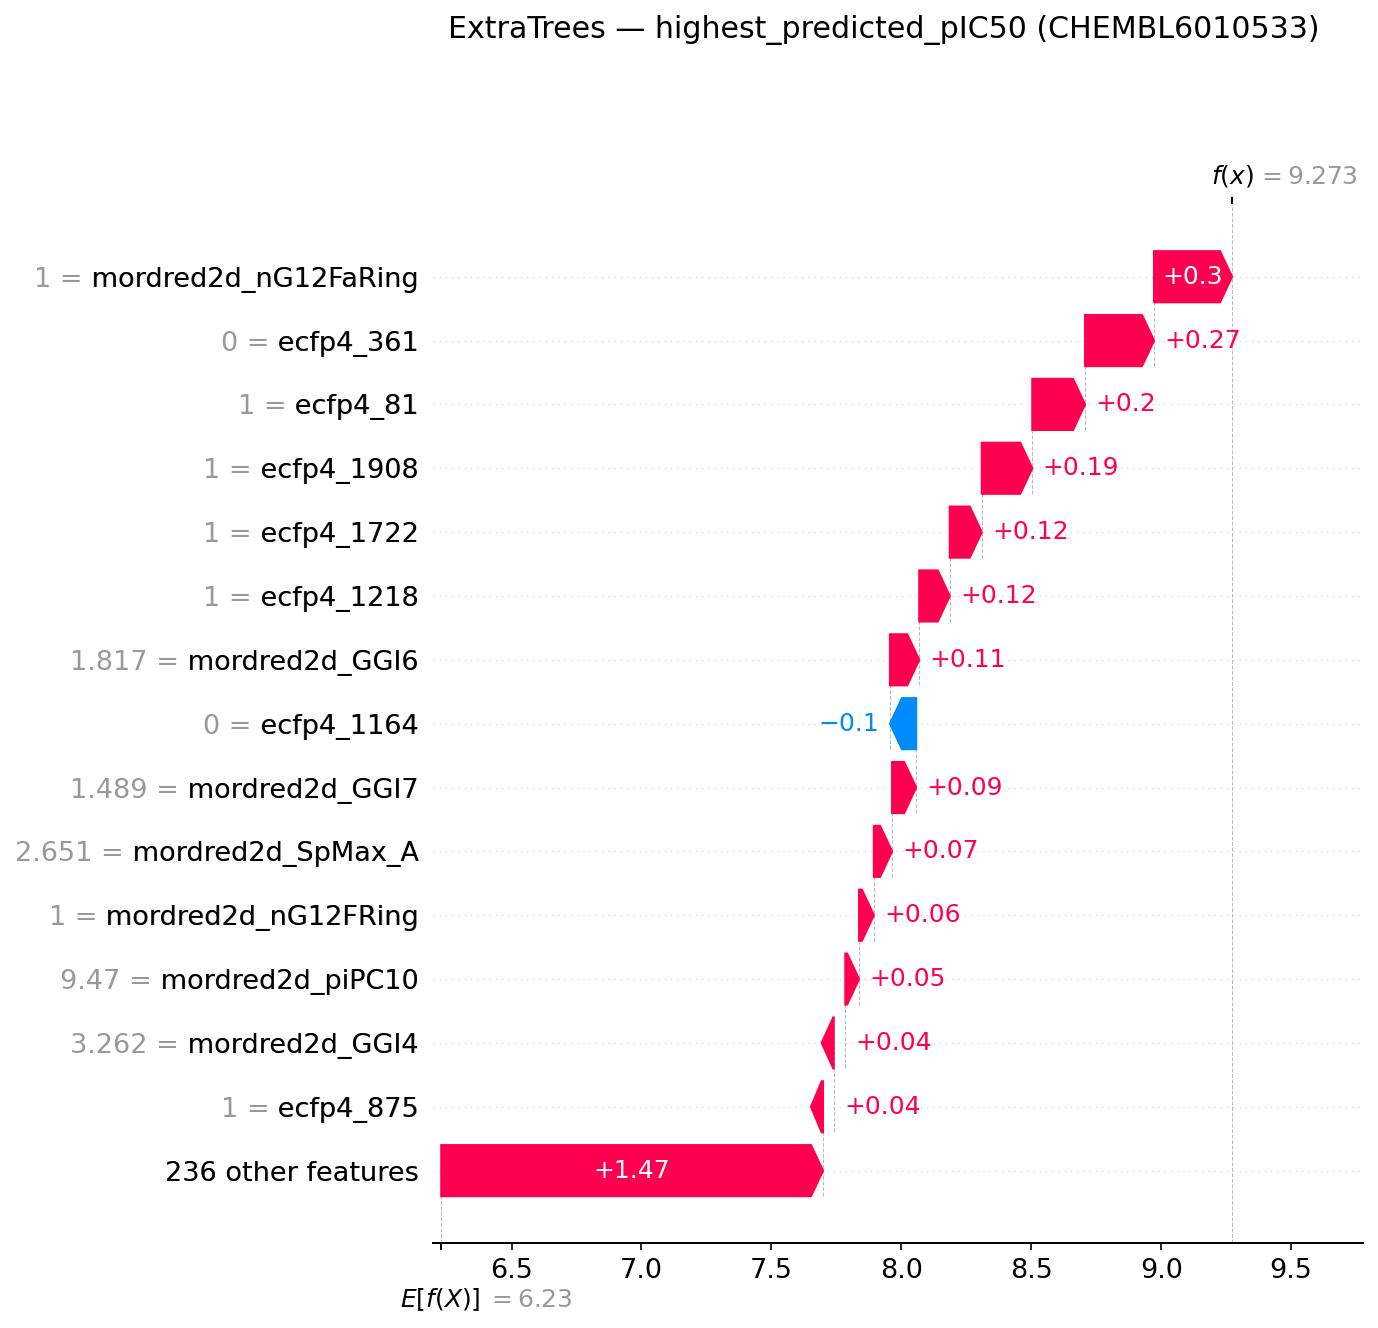

ExtraTrees waterfall plots are shown above; each has also been saved as PNG and PDF.
Top local contributions:


,model,case,chembl_id,feature,feature_value,shap_value,abs_shap
0,ExtraTreesRegressor,lowest_predicted_pIC50,CHEMBL4763815,ecfp4_976,1.000000,-0.391893,0.391893
1,ExtraTreesRegressor,lowest_predicted_pIC50,CHEMBL4763815,ecfp4_1899,1.000000,-0.277862,0.277862
2,ExtraTreesRegressor,lowest_predicted_pIC50,CHEMBL4763815,ecfp4_1722,0.000000,-0.212995,0.212995
3,ExtraTreesRegressor,lowest_predicted_pIC50,CHEMBL4763815,ecfp4_231,1.000000,-0.159438,0.159438
4,ExtraTreesRegressor,lowest_predicted_pIC50,CHEMBL4763815,ecfp4_1164,0.000000,-0.126075,0.126075
5,ExtraTreesRegressor,lowest_predicted_pIC50,CHEMBL4763815,ecfp4_978,1.000000,-0.116807,0.116807
6,ExtraTreesRegressor,lowest_predicted_pIC50,CHEMBL4763815,ecfp4_1969,1.000000,-0.115397,0.115397
7,ExtraTreesRegressor,lowest_predicted_pIC50,CHEMBL4763815,ecfp4_875,0.000000,-0.106600,0.106600
8,ExtraTreesRegressor,lowest_predicted_pIC50,CHEMBL4763815,ecfp4_1693,1.000000,-0.102610,0.102610
9,ExtraTreesRegressor,lowest_predicted_pIC50,CHEMBL4763815,ecfp4_798,1.000000,-0.086216,0.086216


Next: repeat the same global SHAP calculation for CatBoost.


In [9]:
# 8. ExtraTrees local explanations: display and save one waterfall per selected molecule.
et_local_rows = []
for case in et_cases.itertuples(index=False):
    row_index = test_ids.index[test_ids["chembl_id"] == case.chembl_id][0]
    shap.plots.waterfall(extra_trees_shap[row_index], max_display=TOP_LOCAL, show=False)
    fig = plt.gcf()
    fig.suptitle(f"ExtraTrees — {case.case} ({case.chembl_id})", y=1.02)
    stem = f"local_shap_ExtraTreesRegressor_{case.case}_{case.chembl_id}"
    fig.savefig(FIGURE_DIR / f"{stem}.png", dpi=300, bbox_inches="tight")
    fig.savefig(FIGURE_DIR / f"{stem}.pdf", bbox_inches="tight")
    plt.show()
    local = pd.DataFrame({"model": "ExtraTreesRegressor", "case": case.case, "chembl_id": case.chembl_id, "feature": selected_features, "feature_value": X_test.iloc[row_index].to_numpy(dtype=float), "shap_value": values[row_index]})
    et_local_rows.append(local.assign(abs_shap=local["shap_value"].abs()).nlargest(TOP_LOCAL, "abs_shap"))

et_local_top = pd.concat(et_local_rows, ignore_index=True)
et_local_top.to_csv(TABLE_DIR / "local_shap_top_features_ExtraTreesRegressor.csv", index=False)
print("ExtraTrees waterfall plots are shown above; each has also been saved as PNG and PDF.")
print("Top local contributions:")
display(et_local_top)
print("Next: repeat the same global SHAP calculation for CatBoost.")

In [10]:
# 9. Calculate CatBoost SHAP values, check additivity, and show global ranking.
model_name = "CatBoostRegressor"
model = model_bundles[model_name]["model"]
explainer = shap.TreeExplainer(model)
values = np.asarray(explainer.shap_values(X_test, check_additivity=False), dtype=float)
if values.shape != X_test.shape:
    raise ValueError(f"Unexpected SHAP dimensions {values.shape}; expected {X_test.shape}.")
base = np.asarray(explainer.expected_value, dtype=float).reshape(-1)
if base.size == 1:
    base = np.repeat(base[0], len(X_test))
elif base.size != len(X_test):
    raise ValueError(f"Unexpected SHAP base-value dimensions: {base.shape}")

model_predictions = predictions.loc[predictions["model"] == model_name].set_index("chembl_id")
if model_predictions.index.duplicated().any() or set(model_predictions.index) != set(test_ids["chembl_id"]):
    raise ValueError("CatBoost prediction IDs do not match the locked test IDs.")
model_predictions = model_predictions.reindex(test_ids["chembl_id"])
reconstructed = base + values.sum(axis=1)
max_error = float(np.max(np.abs(reconstructed - model_predictions["predicted_pIC50"].to_numpy(dtype=float))))
if not np.allclose(reconstructed, model_predictions["predicted_pIC50"].to_numpy(dtype=float), atol=1e-3, rtol=1e-3):
    raise ValueError(f"CatBoost SHAP additivity check failed; maximum absolute error={max_error:.6g}")

max_error_cat = max_error
catboost_shap = shap.Explanation(values=values, base_values=base, data=X_test.to_numpy(dtype=float), feature_names=selected_features)
importance_cat = pd.DataFrame({"feature": selected_features, "mean_abs_shap": np.abs(values).mean(axis=0), "mean_shap": values.mean(axis=0)}).sort_values("mean_abs_shap", ascending=False, kind="stable").reset_index(drop=True)
importance_cat.insert(0, "model", model_name)
importance_cat.to_csv(TABLE_DIR / "global_shap_importance_CatBoostRegressor.csv", index=False)
pd.DataFrame(values, columns=selected_features).assign(chembl_id=test_ids["chembl_id"].to_numpy()).to_parquet(TABLE_DIR / "test_shap_values_CatBoostRegressor.parquet", index=False)
pd.DataFrame([{"model": model_name, "n_test": len(X_test), "max_abs_additivity_error": max_error}]).to_csv(TABLE_DIR / "shap_additivity_CatBoostRegressor.csv", index=False)
print(f"SHAP matrix: {values.shape}; maximum additivity error: {max_error:.3g}")
print("Top 20 global features by mean absolute SHAP:")
display(importance_cat.head(TOP_GLOBAL))
print("Next: inspect and save the CatBoost global plots.")

SHAP matrix: (1283, 250); maximum additivity error: 1.07e-14
Top 20 global features by mean absolute SHAP:


,model,feature,mean_abs_shap,mean_shap
0,CatBoostRegressor,ecfp4_361,0.171502,-0.020283
1,CatBoostRegressor,mordred2d_SpMax_A,0.094486,0.011971
2,CatBoostRegressor,ecfp4_1722,0.074213,-0.001956
3,CatBoostRegressor,ecfp4_1164,0.073145,-0.007665
4,CatBoostRegressor,ecfp4_875,0.065254,-0.006583
5,CatBoostRegressor,ecfp4_318,0.060162,-0.002747
6,CatBoostRegressor,mordred2d_n6AHRing,0.036518,-0.000463
7,CatBoostRegressor,ecfp4_5,0.035660,-0.001316
8,CatBoostRegressor,mordred2d_SMR_VSA7,0.028675,0.001880
9,CatBoostRegressor,ecfp4_917,0.024477,-0.001333


Next: inspect and save the CatBoost global plots.


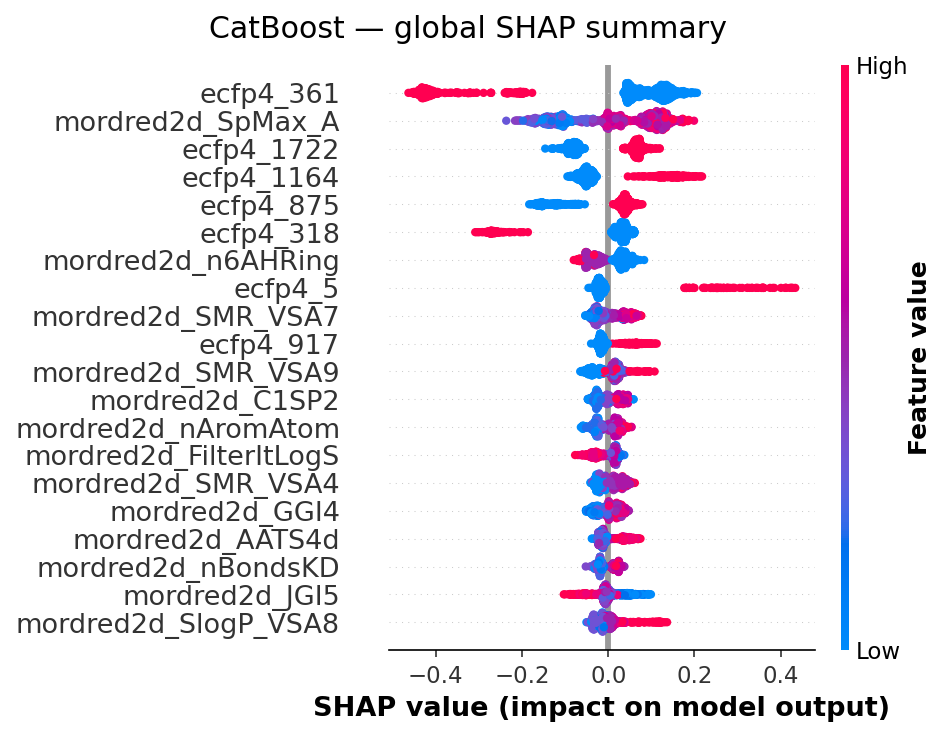

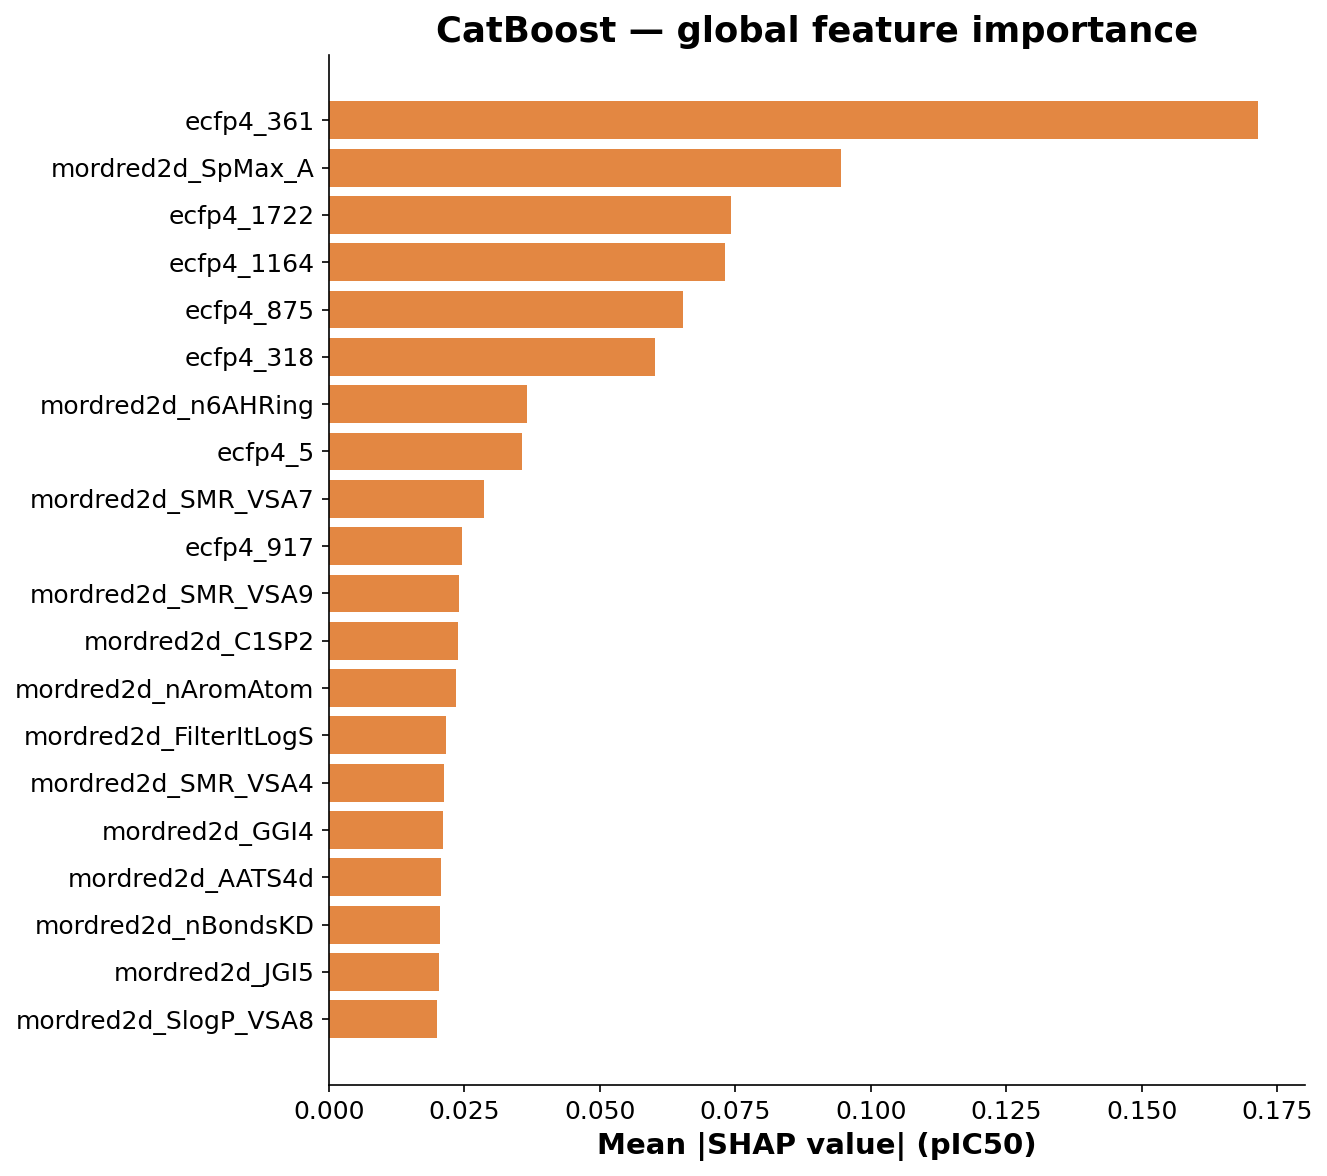

Both CatBoost global plots are displayed above and saved in the Stage 10 figures folder.
Next: select low, median, and high CatBoost predictions for local explanations.


In [11]:
# 10. CatBoost global SHAP plots: beeswarm and mean absolute importance.
top_cat = importance_cat.head(TOP_GLOBAL)
cat_columns = [selected_features.index(feature) for feature in top_cat["feature"]]
shap.summary_plot(values[:, cat_columns], X_test.iloc[:, cat_columns], feature_names=top_cat["feature"].tolist(), max_display=TOP_GLOBAL, show=False, plot_size=None)
fig = plt.gcf()
fig.suptitle("CatBoost — global SHAP summary", y=1.02)
fig.savefig(FIGURE_DIR / "global_shap_beeswarm_CatBoostRegressor.png", dpi=300, bbox_inches="tight")
fig.savefig(FIGURE_DIR / "global_shap_beeswarm_CatBoostRegressor.pdf", bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(9, 8))
plot_cat = top_cat.iloc[::-1]
ax.barh(plot_cat["feature"], plot_cat["mean_abs_shap"], color="#E07A2D", alpha=0.9)
ax.set_xlabel("Mean |SHAP value| (pIC50)")
ax.set_title("CatBoost — global feature importance")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "global_shap_bar_CatBoostRegressor.png", dpi=300, bbox_inches="tight")
fig.savefig(FIGURE_DIR / "global_shap_bar_CatBoostRegressor.pdf", bbox_inches="tight")
plt.show()
print("Both CatBoost global plots are displayed above and saved in the Stage 10 figures folder.")
print("Next: select low, median, and high CatBoost predictions for local explanations.")

In [12]:
# 11. Select CatBoost local cases using predictions only; display the selected molecules.
cat_test_predictions = model_predictions.reset_index()[["chembl_id", "predicted_pIC50"]].sort_values("predicted_pIC50", kind="stable").reset_index(drop=True)
case_positions = {"lowest_predicted_pIC50": 0, "median_predicted_pIC50": len(cat_test_predictions) // 2, "highest_predicted_pIC50": len(cat_test_predictions) - 1}
cat_cases = pd.DataFrame([{"case": label, "chembl_id": cat_test_predictions.iloc[pos]["chembl_id"], "predicted_pIC50": float(cat_test_predictions.iloc[pos]["predicted_pIC50"])} for label, pos in case_positions.items()]).drop_duplicates("chembl_id")
cat_cases.insert(0, "model", "CatBoostRegressor")
cat_cases.to_csv(TABLE_DIR / "local_shap_cases_CatBoostRegressor.csv", index=False)
display(cat_cases)
print("These cases were chosen without using measured test activity.")
print("Next: inspect each molecule's local SHAP waterfall plot.")

,model,case,chembl_id,predicted_pIC50
0,CatBoostRegressor,lowest_predicted_pIC50,CHEMBL4748673,2.993360
1,CatBoostRegressor,median_predicted_pIC50,CHEMBL4848969,6.164433
2,CatBoostRegressor,highest_predicted_pIC50,CHEMBL6051531,9.236537


These cases were chosen without using measured test activity.
Next: inspect each molecule's local SHAP waterfall plot.


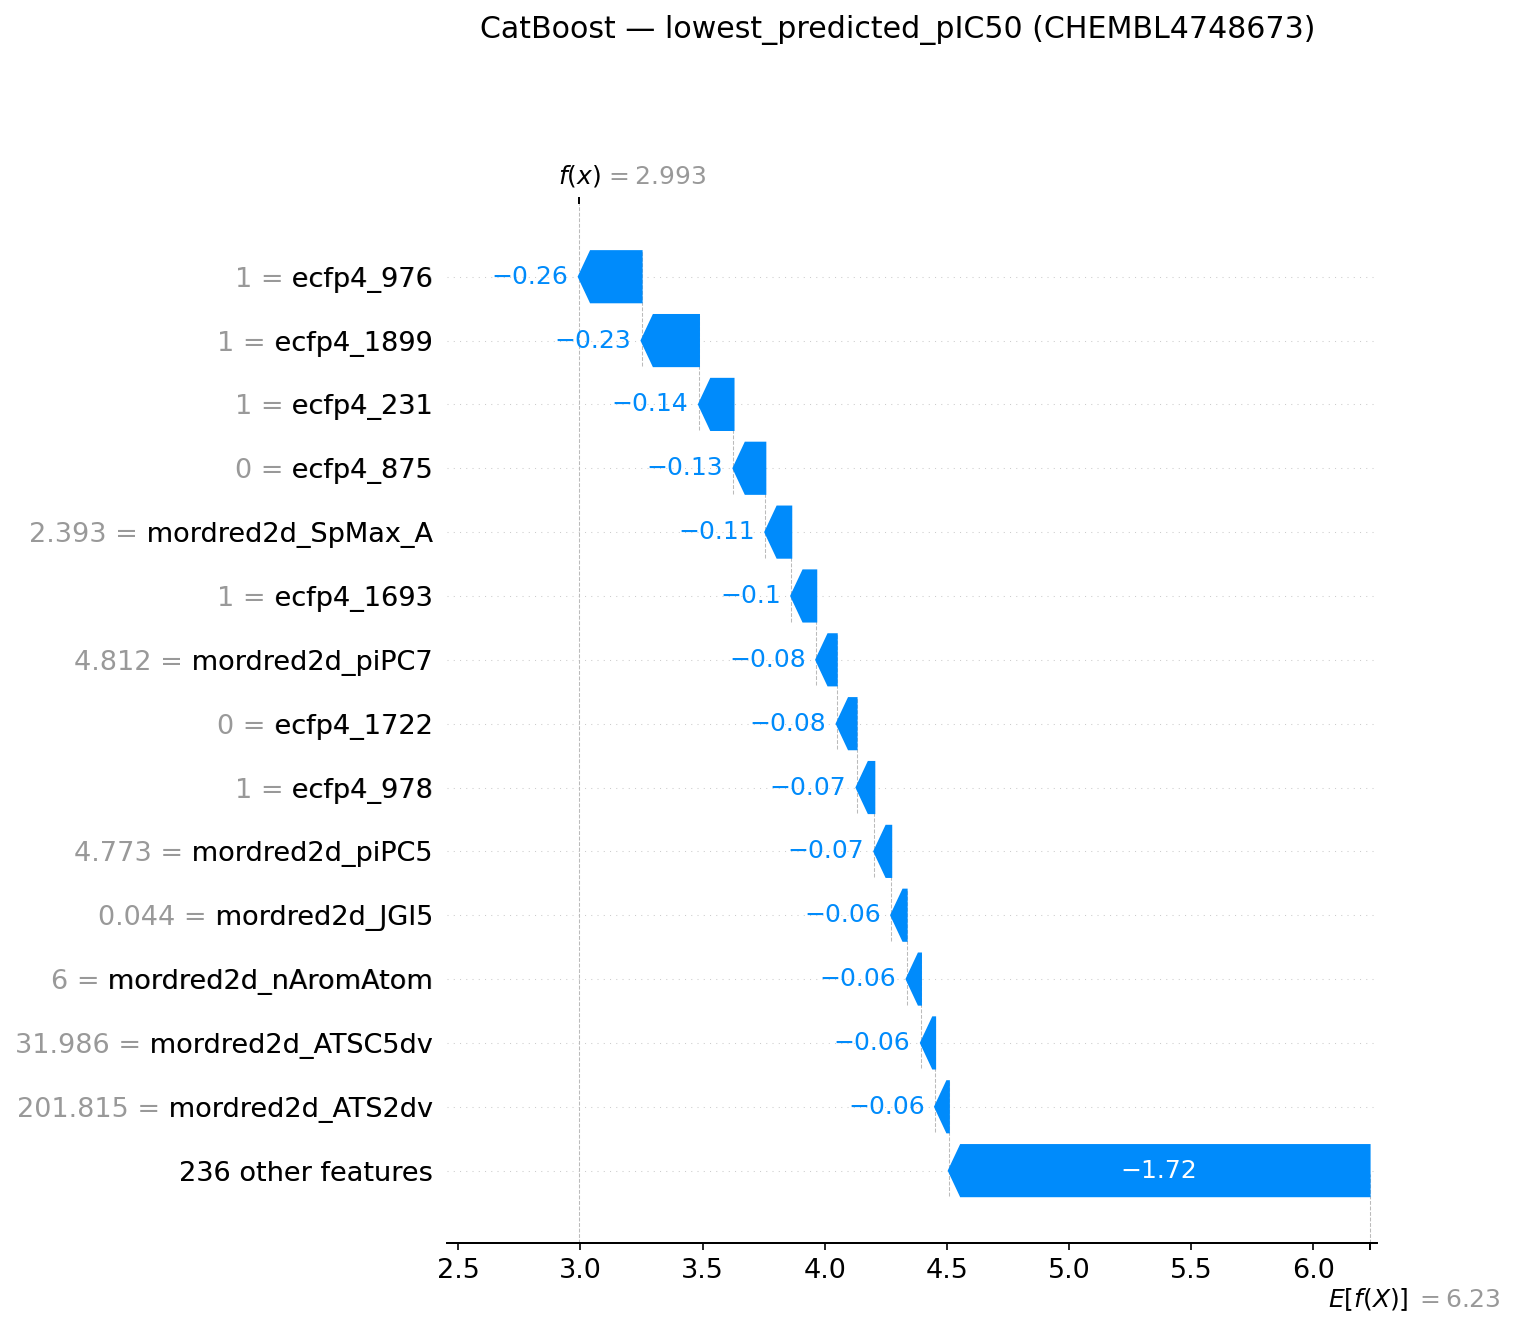

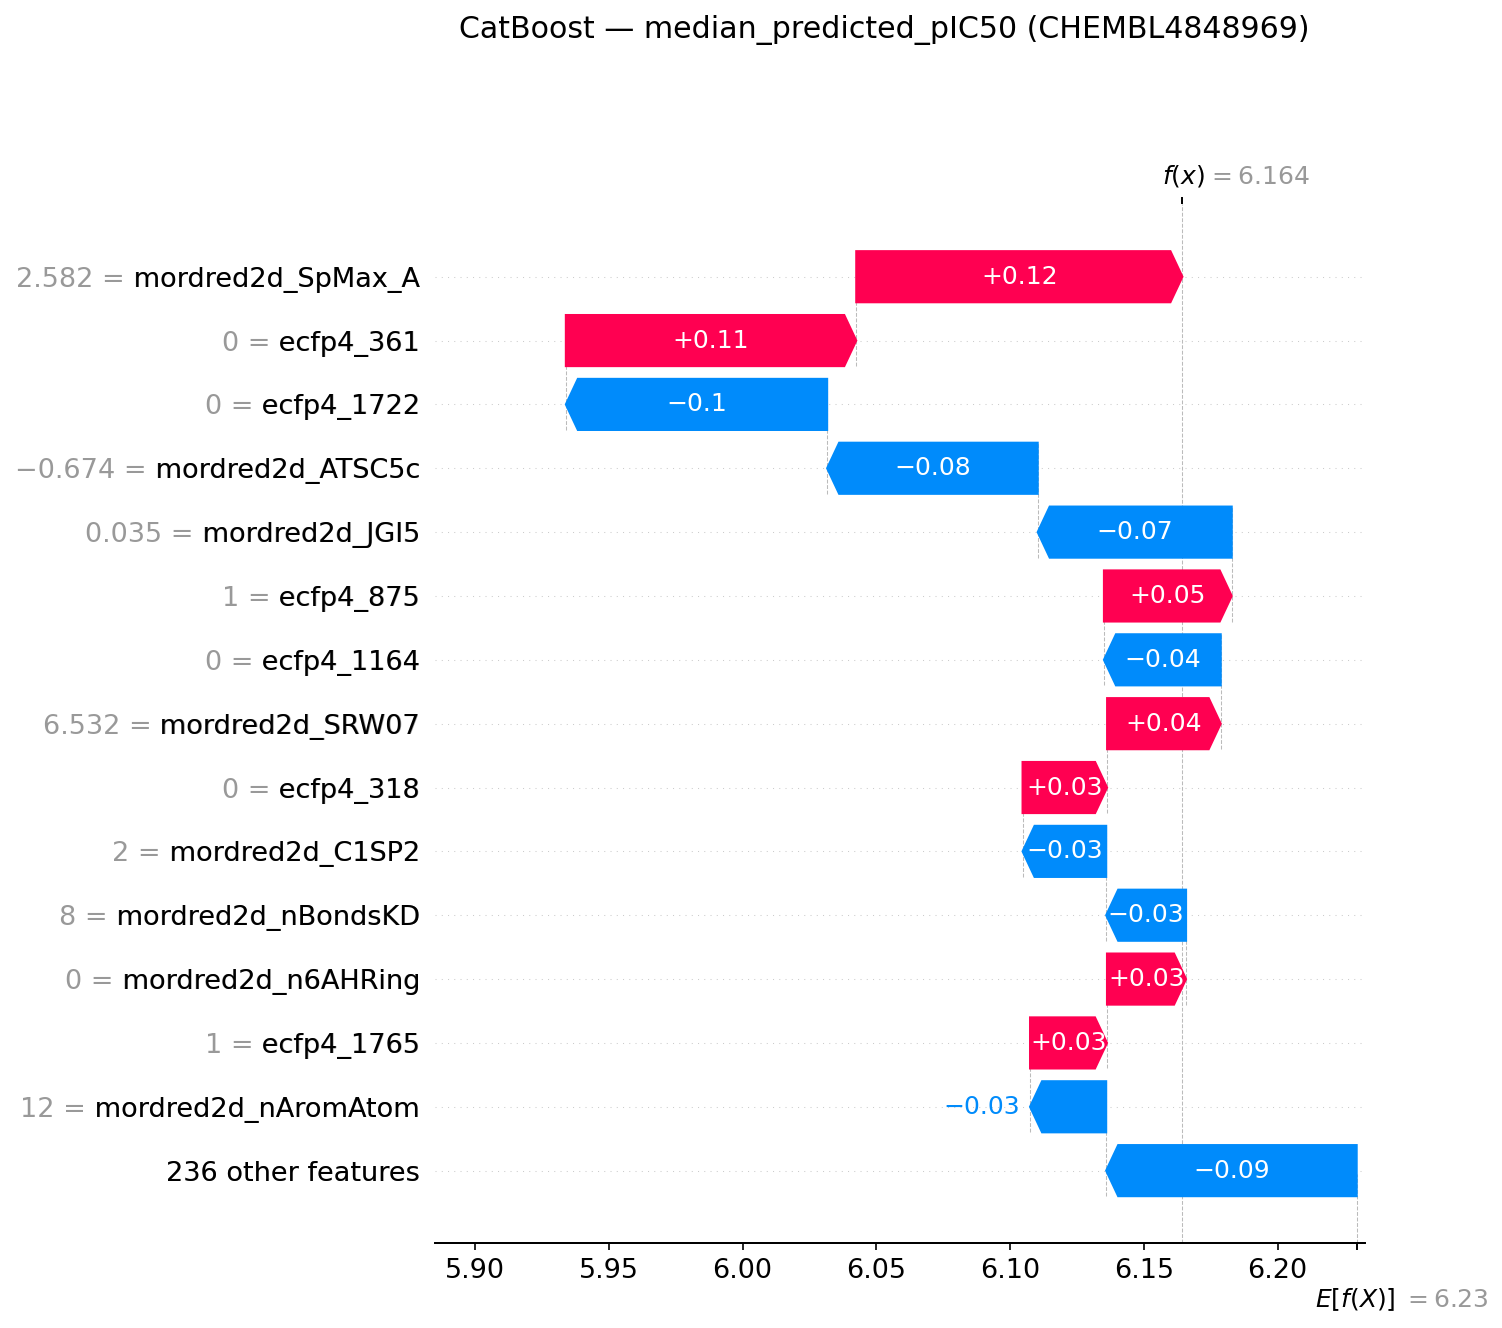

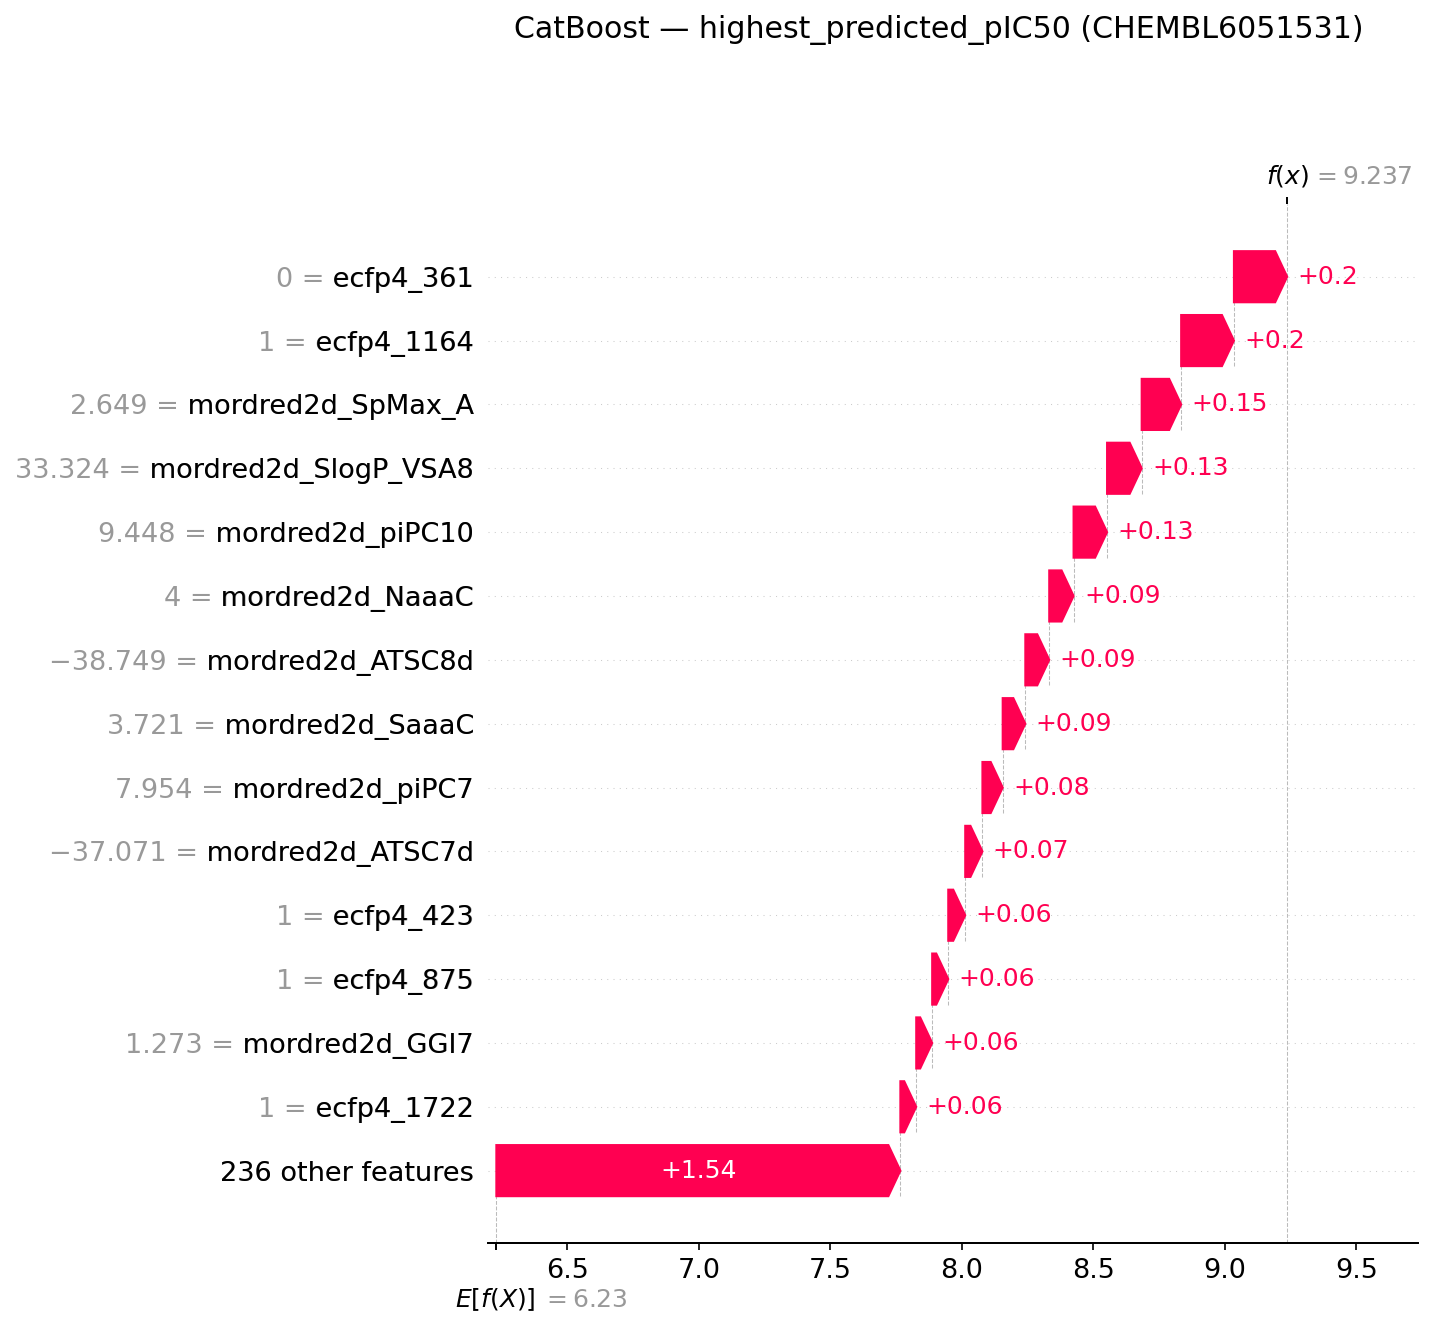

CatBoost waterfall plots are shown above; each has also been saved as PNG and PDF.
Top local contributions:


,model,case,chembl_id,feature,feature_value,shap_value,abs_shap
0,CatBoostRegressor,lowest_predicted_pIC50,CHEMBL4748673,ecfp4_976,1.000000,-0.257087,0.257087
1,CatBoostRegressor,lowest_predicted_pIC50,CHEMBL4748673,ecfp4_1899,1.000000,-0.234815,0.234815
2,CatBoostRegressor,lowest_predicted_pIC50,CHEMBL4748673,ecfp4_231,1.000000,-0.141346,0.141346
3,CatBoostRegressor,lowest_predicted_pIC50,CHEMBL4748673,ecfp4_875,0.000000,-0.130163,0.130163
4,CatBoostRegressor,lowest_predicted_pIC50,CHEMBL4748673,mordred2d_SpMax_A,2.392998,-0.106101,0.106101
5,CatBoostRegressor,lowest_predicted_pIC50,CHEMBL4748673,ecfp4_1693,1.000000,-0.102267,0.102267
6,CatBoostRegressor,lowest_predicted_pIC50,CHEMBL4748673,mordred2d_piPC7,4.811930,-0.083847,0.083847
7,CatBoostRegressor,lowest_predicted_pIC50,CHEMBL4748673,ecfp4_1722,0.000000,-0.081098,0.081098
8,CatBoostRegressor,lowest_predicted_pIC50,CHEMBL4748673,ecfp4_978,1.000000,-0.072669,0.072669
9,CatBoostRegressor,lowest_predicted_pIC50,CHEMBL4748673,mordred2d_piPC5,4.773329,-0.069225,0.069225


Next: review the combined summary and confirm the output files are present.


In [13]:
# 12. CatBoost local explanations: display and save one waterfall per selected molecule.
cat_local_rows = []
for case in cat_cases.itertuples(index=False):
    row_index = test_ids.index[test_ids["chembl_id"] == case.chembl_id][0]
    shap.plots.waterfall(catboost_shap[row_index], max_display=TOP_LOCAL, show=False)
    fig = plt.gcf()
    fig.suptitle(f"CatBoost — {case.case} ({case.chembl_id})", y=1.02)
    stem = f"local_shap_CatBoostRegressor_{case.case}_{case.chembl_id}"
    fig.savefig(FIGURE_DIR / f"{stem}.png", dpi=300, bbox_inches="tight")
    fig.savefig(FIGURE_DIR / f"{stem}.pdf", bbox_inches="tight")
    plt.show()
    local = pd.DataFrame({"model": "CatBoostRegressor", "case": case.case, "chembl_id": case.chembl_id, "feature": selected_features, "feature_value": X_test.iloc[row_index].to_numpy(dtype=float), "shap_value": values[row_index]})
    cat_local_rows.append(local.assign(abs_shap=local["shap_value"].abs()).nlargest(TOP_LOCAL, "abs_shap"))

cat_local_top = pd.concat(cat_local_rows, ignore_index=True)
cat_local_top.to_csv(TABLE_DIR / "local_shap_top_features_CatBoostRegressor.csv", index=False)
print("CatBoost waterfall plots are shown above; each has also been saved as PNG and PDF.")
print("Top local contributions:")
display(cat_local_top)
print("Next: review the combined summary and confirm the output files are present.")

In [14]:
# 13. Combined summary, additivity checks, and saved outputs.
global_shap = pd.concat([importance_et, importance_cat], ignore_index=True)
local_shap = pd.concat([et_local_top, cat_local_top], ignore_index=True)
additivity = pd.DataFrame([
    {"model": "ExtraTreesRegressor", "n_test": len(X_test), "max_abs_additivity_error": max_error_et},
    {"model": "CatBoostRegressor", "n_test": len(X_test), "max_abs_additivity_error": max_error_cat},
])
global_shap.to_csv(TABLE_DIR / "global_shap_importance_both_models.csv", index=False)
local_shap.to_csv(TABLE_DIR / "local_shap_top_features.csv", index=False)
additivity.to_csv(TABLE_DIR / "shap_additivity_check.csv", index=False)

print("Top 10 global features per model:")
display(global_shap.groupby("model", sort=False).head(10).reset_index(drop=True))
print("SHAP additivity check (base value + SHAP sum should reproduce prediction):")
display(additivity)
print(f"\nTables saved to: {TABLE_DIR}")
print(f"Figures saved to: {FIGURE_DIR}")
print(f"Table files: {len(list(TABLE_DIR.iterdir()))}; figure files: {len(list(FIGURE_DIR.iterdir()))}")

Top 10 global features per model:


,model,feature,mean_abs_shap,mean_shap
0,ExtraTreesRegressor,ecfp4_361,0.287584,-0.104999
1,ExtraTreesRegressor,ecfp4_1164,0.138488,0.015830
2,ExtraTreesRegressor,ecfp4_1722,0.092061,0.010109
3,ExtraTreesRegressor,ecfp4_318,0.067803,0.007218
4,ExtraTreesRegressor,ecfp4_875,0.049211,-0.003136
5,ExtraTreesRegressor,ecfp4_917,0.045557,0.004075
6,ExtraTreesRegressor,ecfp4_1658,0.037239,0.007499
7,ExtraTreesRegressor,ecfp4_1409,0.034740,0.001135
8,ExtraTreesRegressor,ecfp4_1696,0.031501,0.001352
9,ExtraTreesRegressor,mordred2d_SpMax_A,0.028294,0.005932


SHAP additivity check (base value + SHAP sum should reproduce prediction):


,model,n_test,max_abs_additivity_error
0,ExtraTreesRegressor,1283,6.885786e-07
1,CatBoostRegressor,1283,1.065814e-14



Tables saved to: C:\Users\USER\Documents\E\Code\outputs\10_shap_interpretation\tables
Figures saved to: C:\Users\USER\Documents\E\Code\outputs\10_shap_interpretation\figures
Table files: 13; figure files: 20


## What this stage produced

- Global SHAP rankings and test-set SHAP values for ExtraTrees and CatBoost.
- One global beeswarm and one mean-absolute-SHAP bar plot per model.
- Low, median, and high prediction waterfall plots for each model.
- An additivity check confirming that the SHAP contributions reconstruct the saved Stage 08 prediction.

All outputs are in `outputs/10_shap_interpretation/`. If a cell raises an error, stop there and share that cell’s full traceback before running later cells.